In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np

In [47]:
data=pd.read_excel('/content/drive/MyDrive/InsuranceSales.xlsx')

In [48]:
data.head()

,CustID,AgentBonus,Age,CustTenure,Channel,Occupation,EducationField,Gender,ExistingProdType,Designation,NumberOfPolicy,MaritalStatus,MonthlyIncome,Complaint,ExistingPolicyTenure,SumAssured,Zone,PaymentMethod,LastMonthCalls,CustCareScore
0,7000000,4409,22.0,4.0,Agent,Salaried,Graduate,Female,3,Manager,2.0,Single,20993.0,1,2.0,806761.0,North,Half Yearly,5,2.0
1,7000001,2214,11.0,2.0,Third Party Partner,Salaried,Graduate,Male,4,Manager,4.0,Divorced,20130.0,0,3.0,294502.0,North,Yearly,7,3.0
2,7000002,4273,26.0,4.0,Agent,Free Lancer,Post Graduate,Male,4,Exe,3.0,Unmarried,17090.0,1,2.0,NaN,North,Yearly,0,3.0
3,7000003,1791,11.0,NaN,Third Party Partner,Salaried,Graduate,Fe male,3,Executive,3.0,Divorced,17909.0,1,2.0,268635.0,West,Half Yearly,0,5.0
4,7000004,2955,6.0,NaN,Agent,Small Business,UG,Male,3,Executive,4.0,Divorced,18468.0,0,4.0,366405.0,West,Half Yearly,2,5.0


In [49]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4520 entries, 0 to 4519
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   CustID                4520 non-null   int64  
 1   AgentBonus            4520 non-null   int64  
 2   Age                   4251 non-null   float64
 3   CustTenure            4294 non-null   float64
 4   Channel               4520 non-null   object 
 5   Occupation            4520 non-null   object 
 6   EducationField        4520 non-null   object 
 7   Gender                4520 non-null   object 
 8   ExistingProdType      4520 non-null   int64  
 9   Designation           4520 non-null   object 
 10  NumberOfPolicy        4475 non-null   float64
 11  MaritalStatus         4520 non-null   object 
 12  MonthlyIncome         4284 non-null   float64
 13  Complaint             4520 non-null   int64  
 14  ExistingPolicyTenure  4336 non-null   float64
 15  SumAssured           

In [50]:
for col in ['Channel', 'Occupation', 'EducationField', 'Gender', 'Designation',
            'MaritalStatus', 'Zone', 'PaymentMethod']:
    print('-----', col)
    print(data[col].value_counts(dropna=False))

----- Channel
Channel
Agent                  3194
Third Party Partner     858
Online                  468
Name: count, dtype: int64
----- Occupation
Occupation
Salaried           2192
Small Business     1918
Large Business      255
Laarge Business     153
Free Lancer           2
Name: count, dtype: int64
----- EducationField
EducationField
Graduate          1870
Under Graduate    1190
Diploma            496
Engineer           408
Post Graduate      252
UG                 230
MBA                 74
Name: count, dtype: int64
----- Gender
Gender
Male       2688
Female     1507
Fe male     325
Name: count, dtype: int64
----- Designation
Designation
Manager           1620
Executive         1535
Senior Manager     676
AVP                336
VP                 226
Exe                127
Name: count, dtype: int64
----- MaritalStatus
MaritalStatus
Married      2268
Single       1254
Divorced      804
Unmarried     194
Name: count, dtype: int64
----- Zone
Zone
West     2566
North    1884
East   

In [51]:
data['Occupation'] = data['Occupation'].replace({'Laarge Business': 'Large Business'})
data['EducationField'] = data['EducationField'].replace({'UG': 'Under Graduate'})
data['Gender'] = data['Gender'].replace({'Fe male': 'Female'})
data['Designation'] = data['Designation'].replace({'Exe': 'Executive'})
data['MaritalStatus'] = data['MaritalStatus'].replace({'Unmarried': 'Single'})

for col in ['Occupation', 'EducationField', 'Gender', 'Designation', 'MaritalStatus']:
    print('-----', col)
    print(data[col].value_counts())

----- Occupation
Occupation
Salaried          2192
Small Business    1918
Large Business     408
Free Lancer          2
Name: count, dtype: int64
----- EducationField
EducationField
Graduate          1870
Under Graduate    1420
Diploma            496
Engineer           408
Post Graduate      252
MBA                 74
Name: count, dtype: int64
----- Gender
Gender
Male      2688
Female    1832
Name: count, dtype: int64
----- Designation
Designation
Executive         1662
Manager           1620
Senior Manager     676
AVP                336
VP                 226
Name: count, dtype: int64
----- MaritalStatus
MaritalStatus
Married     2268
Single      1448
Divorced     804
Name: count, dtype: int64


In [52]:
print('Duplicate rows (ignoring CustID):', data.drop(columns='CustID').duplicated().sum())
print('Duplicate CustIDs:', data['CustID'].duplicated().sum())

data.describe().T.round(1)

Duplicate rows (ignoring CustID): 0
Duplicate CustIDs: 0


,count,mean,std,min,25%,50%,75%,max
CustID,4520.0,7002259.5,1305.0,7000000.0,7001129.8,7002259.5,7003389.2,7004519.0
AgentBonus,4520.0,4077.8,1403.3,1605.0,3027.8,3911.5,4867.2,9608.0
Age,4251.0,14.5,9.0,2.0,7.0,13.0,20.0,58.0
CustTenure,4294.0,14.5,9.0,2.0,7.0,13.0,20.0,57.0
ExistingProdType,4520.0,3.7,1.0,1.0,3.0,4.0,4.0,6.0
NumberOfPolicy,4475.0,3.6,1.5,1.0,2.0,4.0,5.0,6.0
MonthlyIncome,4284.0,22890.3,4885.6,16009.0,19683.5,21606.0,24725.0,38456.0
Complaint,4520.0,0.3,0.5,0.0,0.0,0.0,1.0,1.0
ExistingPolicyTenure,4336.0,4.1,3.3,1.0,2.0,3.0,6.0,25.0
SumAssured,4366.0,619999.7,246234.8,168536.0,439443.2,578976.5,758236.0,1838496.0


In [53]:
missing = data.isnull().sum()
missing = missing[missing > 0]

pd.DataFrame({'Missing': missing,
              'Percent': (missing / len(data) * 100).round(2)}) \
  .sort_values('Missing', ascending=False)

,Missing,Percent
Age,269,5.95
MonthlyIncome,236,5.22
CustTenure,226,5.00
ExistingPolicyTenure,184,4.07
SumAssured,154,3.41
CustCareScore,52,1.15
NumberOfPolicy,45,1.00


In [54]:
miss_cols = ['Age', 'MonthlyIncome', 'CustTenure', 'ExistingPolicyTenure',
             'SumAssured', 'CustCareScore', 'NumberOfPolicy']

for col in miss_cols:
    data[col + '_missing'] = data[col].isnull().astype(int)
    print(col, 'median =', data[col].median())
    data[col] = data[col].fillna(data[col].median())

print('Missing values left:', data.isnull().sum().sum())
print(data[[c + '_missing' for c in miss_cols]].sum())
print(data.shape)

Age median = 13.0
MonthlyIncome median = 21606.0
CustTenure median = 13.0
ExistingPolicyTenure median = 3.0
SumAssured median = 578976.5
CustCareScore median = 3.0
NumberOfPolicy median = 4.0
Missing values left: 0
Age_missing                     269
MonthlyIncome_missing           236
CustTenure_missing              226
ExistingPolicyTenure_missing    184
SumAssured_missing              154
CustCareScore_missing            52
NumberOfPolicy_missing           45
dtype: int64
(4520, 27)


In [55]:
num_cols = ['AgentBonus', 'Age', 'CustTenure', 'MonthlyIncome',
            'ExistingPolicyTenure', 'SumAssured', 'LastMonthCalls']

rows = []
for col in num_cols:
    q1, q3 = data[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((data[col] < q1 - 1.5 * iqr) | (data[col] > q3 + 1.5 * iqr)).sum()
    rows.append([col, round(data[col].skew(), 2), n_out,
                 round(n_out / len(data) * 100, 1), data[col].max()])

pd.DataFrame(rows, columns=['Variable', 'Skewness', 'Outliers', 'Percent', 'Max'])

,Variable,Skewness,Outliers,Percent,Max
0,AgentBonus,0.82,100,2.2,9608.0
1,Age,1.00,105,2.3,58.0
2,CustTenure,0.98,97,2.1,57.0
3,MonthlyIncome,1.43,384,8.5,38456.0
4,ExistingPolicyTenure,1.60,345,7.6,25.0
5,SumAssured,1.00,110,2.4,1838496.0
6,LastMonthCalls,0.81,12,0.3,18.0


In [56]:
for col in ['Age', 'CustTenure', 'MonthlyIncome', 'ExistingPolicyTenure',
            'SumAssured', 'LastMonthCalls']:
    q1, q3 = data[col].quantile([0.25, 0.75])
    upper = q3 + 1.5 * (q3 - q1)
    is_out = data[col] > upper
    print('%-22s outliers: %4d, avg bonus %5.0f | the rest: avg bonus %5.0f' %
          (col, is_out.sum(), data.loc[is_out, 'AgentBonus'].mean(),
           data.loc[~is_out, 'AgentBonus'].mean()))

Age                    outliers:  105, avg bonus  7322 | the rest: avg bonus  4001
CustTenure             outliers:   97, avg bonus  7453 | the rest: avg bonus  4004
MonthlyIncome          outliers:  384, avg bonus  6148 | the rest: avg bonus  3886
ExistingPolicyTenure   outliers:  345, avg bonus  5362 | the rest: avg bonus  3972
SumAssured             outliers:  110, avg bonus  7630 | the rest: avg bonus  3989
LastMonthCalls         outliers:   12, avg bonus  4912 | the rest: avg bonus  4076


In [57]:
import statsmodels.api as sm
from sklearn.model_selection import train_test_split

cat_cols = ['Channel', 'Occupation', 'EducationField', 'Gender',
            'Designation', 'MaritalStatus', 'Zone', 'PaymentMethod']

X = pd.get_dummies(data.drop(columns=['CustID', 'AgentBonus']),
                   columns=cat_cols, drop_first=True, dtype=int)
X = sm.add_constant(X)
y = data['AgentBonus']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=1)

print('X:', X.shape)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Average bonus - train: %.1f, test: %.1f' % (y_train.mean(), y_test.mean()))

X: (4520, 41)
Train: (3164, 41)  Test: (1356, 41)
Average bonus - train: 4082.5, test: 4066.9


In [58]:
olsmod=sm.OLS(y_train, X_train)
olsres=olsmod.fit()
print(olsres.summary())

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     347.3
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:10:21   Log-Likelihood:                -24741.
No. Observations:                3164   AIC:                         4.956e+04
Df Residuals:                    3123   BIC:                         4.981e+04
Df Model:                          40                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [59]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

vif = pd.DataFrame()

vif['Feature'] = X_train.columns

vif['VIF'] = [
    variance_inflation_factor(X_train.values, i)
    for i in range(X_train.shape[1])
]

vif = vif.sort_values(by='VIF', ascending=False)

print(vif)

                          Feature         VIF
22      Occupation_Small Business  413.909867
21            Occupation_Salaried  404.621491
20      Occupation_Large Business  143.877385
29          Designation_Executive   20.175120
35                     Zone_North   18.534294
37                      Zone_West   18.485103
24        EducationField_Graduate   17.485181
23        EducationField_Engineer   16.811022
30            Designation_Manager   14.571937
5                   MonthlyIncome   10.966892
3                ExistingProdType    5.930235
31     Designation_Senior Manager    4.610736
26   EducationField_Post Graduate    4.403835
12          MonthlyIncome_missing    2.961750
27  EducationField_Under Graduate    2.711296
38          PaymentMethod_Monthly    2.672365
32                 Designation_VP    2.550821
40           PaymentMethod_Yearly    2.532118
14   ExistingPolicyTenure_missing    2.054396
25             EducationField_MBA    1.990035
34           MaritalStatus_Single 

In [60]:
X_train1=X_train.drop(['Occupation_Small Business'], axis=1)

olsmod1=sm.OLS(y_train, X_train1)
olsres1=olsmod1.fit()
print(olsres1.summary())

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     355.9
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:10:24   Log-Likelihood:                -24743.
No. Observations:                3164   AIC:                         4.957e+04
Df Residuals:                    3124   BIC:                         4.981e+04
Df Model:                          39                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [61]:
X_train2=X_train.drop(['Occupation_Salaried'], axis=1)

olsmod2=sm.OLS(y_train, X_train2)
olsres2=olsmod2.fit()
print(olsres2.summary())

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     356.0
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:10:25   Log-Likelihood:                -24742.
No. Observations:                3164   AIC:                         4.956e+04
Df Residuals:                    3124   BIC:                         4.981e+04
Df Model:                          39                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [62]:
X_train3=X_train.drop(['Occupation_Large Business'], axis=1)

olsmod3=sm.OLS(y_train, X_train3)
olsres3=olsmod3.fit()
print(olsres3.summary())

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     356.0
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:10:26   Log-Likelihood:                -24742.
No. Observations:                3164   AIC:                         4.956e+04
Df Residuals:                    3124   BIC:                         4.981e+04
Df Model:                          39                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [63]:
X_train4=X_train.drop(['Designation_Executive'], axis=1)

olsmod4=sm.OLS(y_train, X_train4)
olsres4=olsmod4.fit()
print(olsres4.summary())

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     356.3
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:10:26   Log-Likelihood:                -24741.
No. Observations:                3164   AIC:                         4.956e+04
Df Residuals:                    3124   BIC:                         4.980e+04
Df Model:                          39                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [64]:
X_train5=X_train.drop(['Zone_North'], axis=1)

olsmod5=sm.OLS(y_train, X_train5)
olsres5=olsmod5.fit()
print(olsres5.summary())

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     356.2
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:10:27   Log-Likelihood:                -24742.
No. Observations:                3164   AIC:                         4.956e+04
Df Residuals:                    3124   BIC:                         4.981e+04
Df Model:                          39                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [65]:
X_train6=X_train.drop(['Zone_West'], axis=1)

olsmod6=sm.OLS(y_train, X_train6)
olsres6=olsmod6.fit()
print(olsres6.summary())

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     356.2
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:10:28   Log-Likelihood:                -24742.
No. Observations:                3164   AIC:                         4.956e+04
Df Residuals:                    3124   BIC:                         4.981e+04
Df Model:                          39                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [66]:
X_train7=X_train.drop(['MonthlyIncome'], axis=1)

olsmod7=sm.OLS(y_train, X_train7)
olsres7=olsmod7.fit()
print(olsres7.summary())

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.813
Model:                            OLS   Adj. R-squared:                  0.811
Method:                 Least Squares   F-statistic:                     348.4
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:10:29   Log-Likelihood:                -24770.
No. Observations:                3164   AIC:                         4.962e+04
Df Residuals:                    3124   BIC:                         4.986e+04
Df Model:                          39                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [67]:
X_train8=X_train.drop(['ExistingProdType'], axis=1)

olsmod8=sm.OLS(y_train, X_train8)
olsres8=olsmod8.fit()
print(olsres8.summary())

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     356.0
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:10:29   Log-Likelihood:                -24742.
No. Observations:                3164   AIC:                         4.956e+04
Df Residuals:                    3124   BIC:                         4.981e+04
Df Model:                          39                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [68]:
X_train=X_train.drop(['Occupation_Small Business'], axis=1)

vif = pd.DataFrame()

vif['Feature'] = X_train.columns

vif['VIF'] = [
    variance_inflation_factor(X_train.values, i)
    for i in range(X_train.shape[1])
]

vif = vif.sort_values(by='VIF', ascending=False)

print(vif)

                          Feature        VIF
28          Designation_Executive  20.173859
34                     Zone_North  18.531117
36                      Zone_West  18.484607
23        EducationField_Graduate  16.937456
22        EducationField_Engineer  16.749934
20      Occupation_Large Business  16.098092
21            Occupation_Salaried  15.370522
29            Designation_Manager  14.571652
5                   MonthlyIncome  10.965174
3                ExistingProdType   5.928969
30     Designation_Senior Manager   4.610735
25   EducationField_Post Graduate   4.212582
12          MonthlyIncome_missing   2.961563
26  EducationField_Under Graduate   2.711296
37          PaymentMethod_Monthly   2.672182
31                 Designation_VP   2.550796
39           PaymentMethod_Yearly   2.529310
14   ExistingPolicyTenure_missing   2.054381
24             EducationField_MBA   1.958538
33           MaritalStatus_Single   1.930363
32          MaritalStatus_Married   1.915755
8         

In [69]:
X_train9=X_train.drop(['Designation_Executive'], axis=1)

olsmod9=sm.OLS(y_train, X_train9)
olsres9=olsmod9.fit()
print(olsres9.summary())

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     365.4
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:10:31   Log-Likelihood:                -24743.
No. Observations:                3164   AIC:                         4.956e+04
Df Residuals:                    3125   BIC:                         4.980e+04
Df Model:                          38                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [70]:
X_train10=X_train.drop(['Zone_North'], axis=1)

olsmod10=sm.OLS(y_train, X_train10)
olsres10=olsmod10.fit()
print(olsres10.summary())
#

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     365.3
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:10:32   Log-Likelihood:                -24743.
No. Observations:                3164   AIC:                         4.956e+04
Df Residuals:                    3125   BIC:                         4.980e+04
Df Model:                          38                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [71]:
X_train11=X_train.drop(['Zone_West'], axis=1)

olsmod11=sm.OLS(y_train, X_train11)
olsres11=olsmod11.fit()
print(olsres11.summary())

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     365.3
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:10:33   Log-Likelihood:                -24743.
No. Observations:                3164   AIC:                         4.956e+04
Df Residuals:                    3125   BIC:                         4.980e+04
Df Model:                          38                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [72]:
X_train12=X_train.drop(['Occupation_Large Business'], axis=1)

olsmod12=sm.OLS(y_train, X_train12)
olsres12=olsmod12.fit()
print(olsres12.summary())
#

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     365.4
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:10:35   Log-Likelihood:                -24743.
No. Observations:                3164   AIC:                         4.956e+04
Df Residuals:                    3125   BIC:                         4.980e+04
Df Model:                          38                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [73]:
X_train12=X_train.drop(['Occupation_Salaried'], axis=1)

olsmod12=sm.OLS(y_train, X_train12)
olsres12=olsmod12.fit()
print(olsres12.summary())
#

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     365.3
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:10:36   Log-Likelihood:                -24743.
No. Observations:                3164   AIC:                         4.956e+04
Df Residuals:                    3125   BIC:                         4.980e+04
Df Model:                          38                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [74]:
X_train13=X_train.drop(['MonthlyIncome'], axis=1)

olsmod13=sm.OLS(y_train, X_train13)
olsres13=olsmod13.fit()
print(olsres13.summary())
#

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.813
Model:                            OLS   Adj. R-squared:                  0.811
Method:                 Least Squares   F-statistic:                     357.3
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:10:37   Log-Likelihood:                -24771.
No. Observations:                3164   AIC:                         4.962e+04
Df Residuals:                    3125   BIC:                         4.986e+04
Df Model:                          38                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [75]:
X_train14=X_train.drop(['ExistingProdType'], axis=1)

olsmod14=sm.OLS(y_train, X_train14)
olsres14=olsmod14.fit()
print(olsres14.summary())
#

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     365.1
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:10:38   Log-Likelihood:                -24743.
No. Observations:                3164   AIC:                         4.956e+04
Df Residuals:                    3125   BIC:                         4.980e+04
Df Model:                          38                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [76]:
X_train=X_train.drop(['Designation_Executive'], axis=1)

vif = pd.DataFrame()

vif['Feature'] = X_train.columns

vif['VIF'] = [
    variance_inflation_factor(X_train.values, i)
    for i in range(X_train.shape[1])
]

vif = vif.sort_values(by='VIF', ascending=False)

print(vif)

                          Feature        VIF
33                     Zone_North  18.523742
35                      Zone_West  18.468438
23        EducationField_Graduate  16.935330
22        EducationField_Engineer  16.734925
20      Occupation_Large Business  16.093068
21            Occupation_Salaried  15.362727
25   EducationField_Post Graduate   4.211266
3                ExistingProdType   4.156500
5                   MonthlyIncome   3.747796
26  EducationField_Under Graduate   2.708675
30                 Designation_VP   2.538300
36          PaymentMethod_Monthly   2.212057
38           PaymentMethod_Yearly   2.105336
14   ExistingPolicyTenure_missing   2.023642
24             EducationField_MBA   1.958125
32           MaritalStatus_Single   1.930277
31          MaritalStatus_Married   1.915637
8                      SumAssured   1.821793
15             SumAssured_missing   1.730183
29     Designation_Senior Manager   1.588747
28            Designation_Manager   1.533347
17        

In [77]:
X_train15=X_train.drop(['Zone_North'], axis=1)

olsmod15=sm.OLS(y_train, X_train15)
olsres15=olsmod15.fit()
print(olsres15.summary())

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     375.3
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:10:41   Log-Likelihood:                -24743.
No. Observations:                3164   AIC:                         4.956e+04
Df Residuals:                    3126   BIC:                         4.979e+04
Df Model:                          37                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [78]:
X_train16=X_train.drop(['Zone_West'], axis=1)
olsmod16=sm.OLS(y_train, X_train16)
olsres16=olsmod16.fit()
print(olsres16.summary())

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     375.3
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:10:42   Log-Likelihood:                -24743.
No. Observations:                3164   AIC:                         4.956e+04
Df Residuals:                    3126   BIC:                         4.979e+04
Df Model:                          37                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [79]:
X_train17=X_train.drop(['Occupation_Large Business'], axis=1)

olsmod17=sm.OLS(y_train, X_train17)
olsres17=olsmod17.fit()
print(olsres17.summary())
#

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     375.4
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:10:43   Log-Likelihood:                -24743.
No. Observations:                3164   AIC:                         4.956e+04
Df Residuals:                    3126   BIC:                         4.979e+04
Df Model:                          37                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [80]:
X_train18=X_train.drop(['Occupation_Salaried'], axis=1)

olsmod18=sm.OLS(y_train, X_train18)
olsres18=olsmod18.fit()
print(olsres18.summary())
#

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     375.2
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:10:44   Log-Likelihood:                -24743.
No. Observations:                3164   AIC:                         4.956e+04
Df Residuals:                    3126   BIC:                         4.979e+04
Df Model:                          37                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [81]:
X_train=X_train.drop(['Occupation_Large Business'], axis=1)

vif = pd.DataFrame()

vif['Feature'] = X_train.columns

vif['VIF'] = [
    variance_inflation_factor(X_train.values, i)
    for i in range(X_train.shape[1])
]

vif = vif.sort_values(by='VIF', ascending=False)

print(vif)

                          Feature        VIF
32                     Zone_North  18.523570
34                      Zone_West  18.468391
22        EducationField_Graduate  15.325598
20            Occupation_Salaried  13.692482
3                ExistingProdType   4.150157
24   EducationField_Post Graduate   3.908808
5                   MonthlyIncome   3.747672
25  EducationField_Under Graduate   2.708123
29                 Designation_VP   2.537864
35          PaymentMethod_Monthly   2.209956
37           PaymentMethod_Yearly   2.103179
14   ExistingPolicyTenure_missing   2.022309
31           MaritalStatus_Single   1.930180
30          MaritalStatus_Married   1.915590
23             EducationField_MBA   1.869659
8                      SumAssured   1.821712
15             SumAssured_missing   1.729211
21        EducationField_Engineer   1.661743
28     Designation_Senior Manager   1.587927
27            Designation_Manager   1.533271
17         NumberOfPolicy_missing   1.526008
16        

In [82]:
olsmod19=sm.OLS(y_train, X_train)
olsres19=olsmod19.fit()
print(olsres19.summary())

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     375.4
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:13:24   Log-Likelihood:                -24743.
No. Observations:                3164   AIC:                         4.956e+04
Df Residuals:                    3126   BIC:                         4.979e+04
Df Model:                          37                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [83]:
X_train20=X_train.drop(['CustCareScore_missing'], axis=1)

olsmod20=sm.OLS(y_train, X_train20)
olsres20=olsmod20.fit()
print(olsres20.summary())
#

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     386.0
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:17:20   Log-Likelihood:                -24743.
No. Observations:                3164   AIC:                         4.956e+04
Df Residuals:                    3127   BIC:                         4.978e+04
Df Model:                          36                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [84]:
X_train21=X_train.drop(['ExistingPolicyTenure_missing'], axis=1)

olsmod21=sm.OLS(y_train, X_train21)
olsres21=olsmod21.fit()
print(olsres21.summary())
#

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     386.0
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:19:59   Log-Likelihood:                -24743.
No. Observations:                3164   AIC:                         4.956e+04
Df Residuals:                    3127   BIC:                         4.978e+04
Df Model:                          36                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [85]:
X_train22=X_train.drop(['CustCareScore_missing'], axis=1)

olsmod22=sm.OLS(y_train, X_train22)
olsres22=olsmod22.fit()
print(olsres22.summary())
#

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     386.0
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:21:58   Log-Likelihood:                -24743.
No. Observations:                3164   AIC:                         4.956e+04
Df Residuals:                    3127   BIC:                         4.978e+04
Df Model:                          36                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [89]:
X_train23=X_train.drop(['ExistingPolicyTenure_missing'], axis=1)

olsmod23=sm.OLS(y_train, X_train23)
olsres23=olsmod23.fit()
print(olsres23.summary())
#

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     386.0
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:25:35   Log-Likelihood:                -24743.
No. Observations:                3164   AIC:                         4.956e+04
Df Residuals:                    3127   BIC:                         4.978e+04
Df Model:                          36                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [90]:
X_train24=X_train.drop(['CustCareScore_missing'], axis=1)

olsmod24=sm.OLS(y_train, X_train24)
olsres24=olsmod24.fit()
print(olsres24.summary())
#
#

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     386.0
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:25:46   Log-Likelihood:                -24743.
No. Observations:                3164   AIC:                         4.956e+04
Df Residuals:                    3127   BIC:                         4.978e+04
Df Model:                          36                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [91]:
X_train25=X_train.drop(['ExistingPolicyTenure_missing'], axis=1)

olsmod25=sm.OLS(y_train, X_train25)
olsres25=olsmod25.fit()
print(olsres25.summary())
#
#

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     386.0
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:26:11   Log-Likelihood:                -24743.
No. Observations:                3164   AIC:                         4.956e+04
Df Residuals:                    3127   BIC:                         4.978e+04
Df Model:                          36                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [92]:
X_train25=X_train.drop(['CustCareScore_missing'], axis=1)

olsmod25=sm.OLS(y_train, X_train25)
olsres25=olsmod25.fit()
print(olsres25.summary())
#
#

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     386.0
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:27:27   Log-Likelihood:                -24743.
No. Observations:                3164   AIC:                         4.956e+04
Df Residuals:                    3127   BIC:                         4.978e+04
Df Model:                          36                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [93]:
X_train=X_train.drop(['ExistingPolicyTenure_missing'], axis=1)

olsmod=sm.OLS(y_train, X_train)
olsres=olsmod.fit()
print(olsres.summary())

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     386.0
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:29:37   Log-Likelihood:                -24743.
No. Observations:                3164   AIC:                         4.956e+04
Df Residuals:                    3127   BIC:                         4.978e+04
Df Model:                          36                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [95]:
X_train=X_train.drop(['CustCareScore_missing'], axis=1)

olsmod=sm.OLS(y_train, X_train)
olsres=olsmod.fit()
print(olsres.summary())

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     397.1
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:31:00   Log-Likelihood:                -24743.
No. Observations:                3164   AIC:                         4.956e+04
Df Residuals:                    3128   BIC:                         4.978e+04
Df Model:                          35                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [96]:
X_train=X_train.drop(['CustTenure_missing'], axis=1)

olsmod=sm.OLS(y_train, X_train)
olsres=olsmod.fit()
print(olsres.summary())

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     408.9
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:31:54   Log-Likelihood:                -24743.
No. Observations:                3164   AIC:                         4.956e+04
Df Residuals:                    3129   BIC:                         4.977e+04
Df Model:                          34                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [97]:
X_train=X_train.drop(['NumberOfPolicy'], axis=1)

olsmod=sm.OLS(y_train, X_train)
olsres=olsmod.fit()
print(olsres.summary())

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     421.4
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:34:56   Log-Likelihood:                -24743.
No. Observations:                3164   AIC:                         4.955e+04
Df Residuals:                    3130   BIC:                         4.976e+04
Df Model:                          33                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [98]:
X_train=X_train.drop(['Age_missing'], axis=1)

olsmod=sm.OLS(y_train, X_train)
olsres=olsmod.fit()
print(olsres.summary())

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     434.6
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:36:39   Log-Likelihood:                -24743.
No. Observations:                3164   AIC:                         4.955e+04
Df Residuals:                    3131   BIC:                         4.975e+04
Df Model:                          32                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [99]:
X_train=X_train.drop(['NumberOfPolicy_missing'], axis=1)

olsmod=sm.OLS(y_train, X_train)
olsres=olsmod.fit()
print(olsres.summary())

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     448.4
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:37:31   Log-Likelihood:                -24744.
No. Observations:                3164   AIC:                         4.955e+04
Df Residuals:                    3132   BIC:                         4.975e+04
Df Model:                          31                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [100]:
X_train=X_train.drop(['ExistingProdType'], axis=1)

olsmod=sm.OLS(y_train, X_train)
olsres=olsmod.fit()
print(olsres.summary())

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     463.2
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:38:15   Log-Likelihood:                -24745.
No. Observations:                3164   AIC:                         4.955e+04
Df Residuals:                    3133   BIC:                         4.974e+04
Df Model:                          30                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [101]:
X_train=X_train.drop(['LastMonthCalls'], axis=1)

olsmod=sm.OLS(y_train, X_train)
olsres=olsmod.fit()
print(olsres.summary())

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     478.9
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:39:08   Log-Likelihood:                -24746.
No. Observations:                3164   AIC:                         4.955e+04
Df Residuals:                    3134   BIC:                         4.973e+04
Df Model:                          29                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [102]:
X_train=X_train.drop(['CustCareScore'], axis=1)

olsmod=sm.OLS(y_train, X_train)
olsres=olsmod.fit()
print(olsres.summary())
#

                            OLS Regression Results                            
Dep. Variable:             AgentBonus   R-squared:                       0.816
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     495.8
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:39:55   Log-Likelihood:                -24747.
No. Observations:                3164   AIC:                         4.955e+04
Df Residuals:                    3135   BIC:                         4.973e+04
Df Model:                          28                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [103]:
df_pred=pd.DataFrame()

df_pred['Actual Values']=y_train.values.flatten()
df_pred['Fitted Values']=olsres.fittedvalues.values
df_pred['Residuals']=olsres.resid.values

df_pred.head()

,Actual Values,Fitted Values,Residuals
0,3941,3566.298069,374.701931
1,5148,4390.661730,757.338270
2,3084,3093.822032,-9.822032
3,2589,2629.446368,-40.446368
4,4145,4269.172706,-124.172706


In [105]:
import matplotlib.pyplot as plt
import seaborn as sns

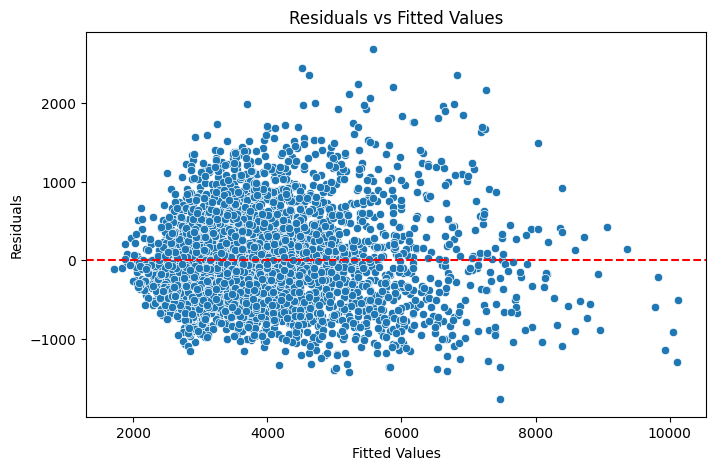

In [106]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x='Fitted Values',
    y='Residuals',
    data=df_pred
)

plt.axhline(y=0, color='red', linestyle='--')
plt.title('Residuals vs Fitted Values')
plt.show()

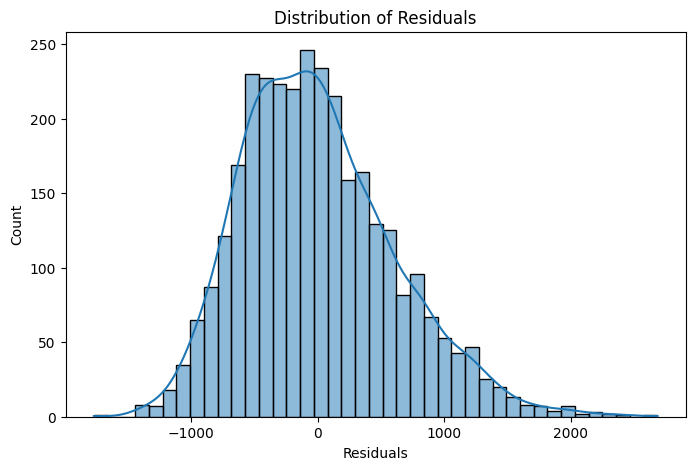

In [107]:
plt.figure(figsize=(8, 5))

sns.histplot(df_pred['Residuals'], kde=True)

plt.title('Distribution of Residuals')
plt.xlabel('Residuals')
plt.show()

In [108]:
import pylab
from scipy.stats import stats

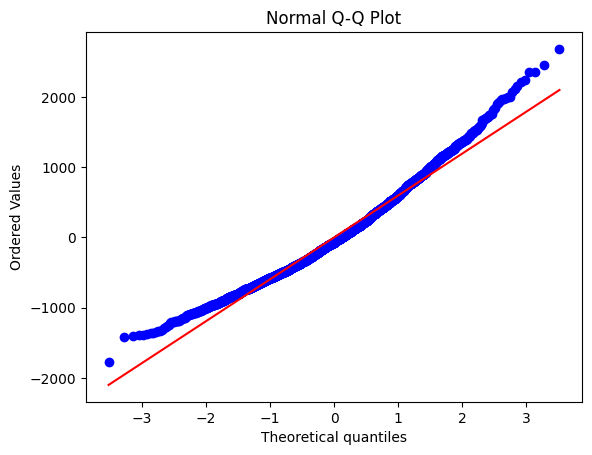

In [110]:
from scipy import stats
import pylab

stats.probplot(
    df_pred['Residuals'],
    dist='norm',
    plot=pylab
)

pylab.title('Normal Q-Q Plot')
pylab.show()

In [111]:
stats.shapiro(df_pred['Residuals'])

ShapiroResult(statistic=np.float64(0.9785659276621166), pvalue=np.float64(1.8749108581114662e-21))

In [112]:
from statsmodels.stats.diagnostic import het_goldfeldquandt

gq_test = het_goldfeldquandt(
    olsres.resid,
    olsres.model.exog
)

print("F-statistic:", gq_test[0])
print("p-value:", gq_test[1])
print("Alternative:", gq_test[2])

F-statistic: 1.0673697569351899
p-value: 0.09951255148043332
Alternative: increasing


/tmp/ipykernel_6442/2902000500.py:3: FutureWarning: het_goldfeldquandt currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a GoldfeldQuandtResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  gq_test = het_goldfeldquandt(


In [113]:
X_test.columns

Index(['const', 'Age', 'CustTenure', 'ExistingProdType', 'NumberOfPolicy',
       'MonthlyIncome', 'Complaint', 'ExistingPolicyTenure', 'SumAssured',
       'LastMonthCalls', 'CustCareScore', 'Age_missing',
       'MonthlyIncome_missing', 'CustTenure_missing',
       'ExistingPolicyTenure_missing', 'SumAssured_missing',
       'CustCareScore_missing', 'NumberOfPolicy_missing', 'Channel_Online',
       'Channel_Third Party Partner', 'Occupation_Large Business',
       'Occupation_Salaried', 'Occupation_Small Business',
       'EducationField_Engineer', 'EducationField_Graduate',
       'EducationField_MBA', 'EducationField_Post Graduate',
       'EducationField_Under Graduate', 'Gender_Male', 'Designation_Executive',
       'Designation_Manager', 'Designation_Senior Manager', 'Designation_VP',
       'MaritalStatus_Married', 'MaritalStatus_Single', 'Zone_North',
       'Zone_South', 'Zone_West', 'PaymentMethod_Monthly',
       'PaymentMethod_Quarterly', 'PaymentMethod_Yearly'],
      dt

In [114]:
X_train.columns

Index(['const', 'Age', 'CustTenure', 'MonthlyIncome', 'Complaint',
       'ExistingPolicyTenure', 'SumAssured', 'MonthlyIncome_missing',
       'SumAssured_missing', 'Channel_Online', 'Channel_Third Party Partner',
       'Occupation_Salaried', 'EducationField_Engineer',
       'EducationField_Graduate', 'EducationField_MBA',
       'EducationField_Post Graduate', 'EducationField_Under Graduate',
       'Gender_Male', 'Designation_Manager', 'Designation_Senior Manager',
       'Designation_VP', 'MaritalStatus_Married', 'MaritalStatus_Single',
       'Zone_North', 'Zone_South', 'Zone_West', 'PaymentMethod_Monthly',
       'PaymentMethod_Quarterly', 'PaymentMethod_Yearly'],
      dtype='object')

In [115]:
X_test = X_test[X_train.columns]

In [116]:
print(X_train.columns.equals(X_test.columns))

True


In [117]:
pred_test = olsres.predict(X_test)
pred_test=np.round(pred_test)

In [119]:
from sklearn.metrics import mean_squared_error

In [120]:
rmse1=np.sqrt(mean_squared_error(y_test, pred_test))
print('RMSE:', rmse1)

RMSE: 619.4937365910298


In [122]:
rmse2=np.sqrt(mean_squared_error(y_train, df_pred['Fitted Values']))
print('RMSE:', rmse2)

RMSE: 603.316631132816


In [123]:
from sklearn.metrics import r2_score, mean_absolute_error


In [124]:
print("Train MAE:", mean_absolute_error(y_train, df_pred['Fitted Values']))
print("Test MAE:", mean_absolute_error(y_test, pred_test))

Train MAE: 477.40028666011114
Test MAE: 493.07522123893807
